Number of outliers: 17121

Correlation:
                    pickup_longitude  pickup_latitude  dropoff_longitude  \
pickup_longitude           1.000000        -0.815878           0.833047   
pickup_latitude           -0.815878         1.000000          -0.774615   
dropoff_longitude          0.833047        -0.774615           1.000000   
dropoff_latitude          -0.846383         0.701959          -0.916715   
passenger_count           -0.000247        -0.001695           0.000073   
fare_amount                0.010420        -0.008441           0.009064   

                   dropoff_latitude  passenger_count  fare_amount  
pickup_longitude          -0.846383        -0.000247     0.010420  
pickup_latitude            0.701959        -0.001695    -0.008441  
dropoff_longitude         -0.916715         0.000073     0.009064  
dropoff_latitude           1.000000        -0.000686    -0.011098  
passenger_count           -0.000686         1.000000     0.009616  
fare_amount              

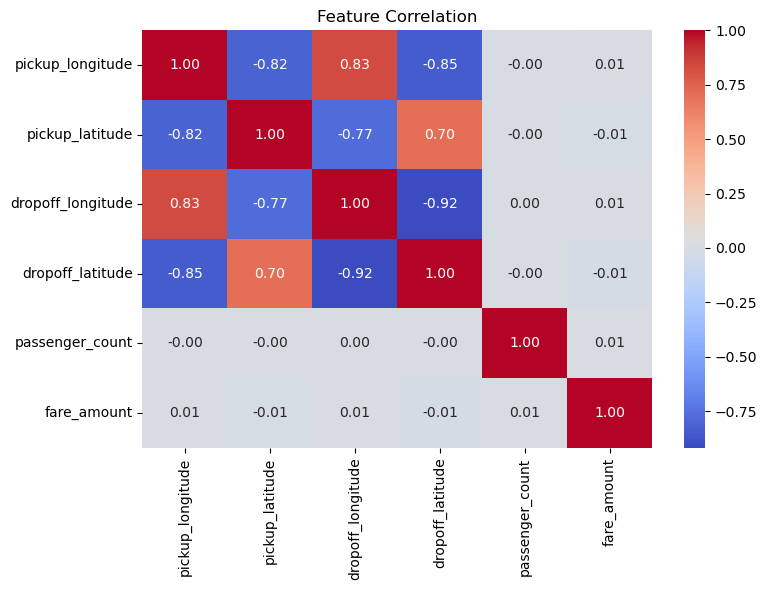


 Linear Regression
R2 Score: -1.9465516647665382e-05
RMSE: 10.14071794317557

 Random Forest
R2 Score: 0.7205615394376237
RMSE: 5.360527971157914


In [4]:
import matplotlib.pyplot as plt
import seaborn as sns

import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import r2_score, mean_squared_error

# Load dataset
df = pd.read_csv("uber.csv")

# Preprocessing
df = df.dropna()
df = df[(df["fare_amount"] > 0) &
        (df["passenger_count"] > 0)]

# Identify outliers
Q1 = df["fare_amount"].quantile(0.25)
Q3 = df["fare_amount"].quantile(0.75)
IQR = Q3 - Q1

outliers = df[
    (df["fare_amount"] < Q1 - 1.5 * IQR) |
    (df["fare_amount"] > Q3 + 1.5 * IQR)
]
print("Number of outliers:", len(outliers))

# Select features and target
X = df[[
    "pickup_longitude", "pickup_latitude",
    "dropoff_longitude", "dropoff_latitude",
    "passenger_count"
]]
y = df["fare_amount"]

# Correlation
print("\nCorrelation:\n", df[X.columns.tolist() + ["fare_amount"]].corr())

 
# 6. Correlation heatmap
plt.figure(figsize=(8, 6))

sns.heatmap(
    df[["pickup_longitude", "pickup_latitude",
    "dropoff_longitude", "dropoff_latitude",
    "passenger_count","fare_amount"]].corr(),
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Feature Correlation")
plt.tight_layout()
plt.show()

# Split data
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

# Linear Regression
lr = LinearRegression()
lr.fit(X_train, y_train)
pred1 = lr.predict(X_test)

# Random Forest Regression
rf = RandomForestRegressor(n_estimators=50, random_state=42)
rf.fit(X_train, y_train)
pred2 = rf.predict(X_test)

# Evaluation
for name, pred in [
    ("Linear Regression", pred1),
    ("Random Forest", pred2)
]:
    print("\n", name)
    print("R2 Score:", r2_score(y_test, pred))
    print("RMSE:", np.sqrt(mean_squared_error(y_test, pred)))
